# From teacher labels to a deployed potential: a walkthrough

This notebook runs a miniature version of the alloy-mlip-bench pipeline end
to end: generate a small teacher-labeled dataset, train a compact potential,
deploy it as an ASE calculator, and benchmark it against the teacher on a
real property. Every number below is computed live when the notebook
executes; the committed full-run results appear only in the last section and
are labeled as such.

One thing to keep straight throughout: the labels are **surrogate model
labels** from a pretrained universal potential (CHGNet), not DFT. Real DFT
enters only as Materials Project validation anchors.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from alloybench.anchors import load_anchors
from alloybench.calculators import TorchPotentialCalculator, get_calculator
from alloybench.evaluate import evaluate_model
from alloybench.labeling import label_frames
from alloybench.lattice import rattle_batch, strain_batch
from alloybench.models import fit_element_refs, set_element_refs
from alloybench.properties import eos_scan, nve_drift, speed_benchmark
from alloybench.splits import group_split
from alloybench.train import build_model, prepare_frames, train_potential

COLOR = {"compact": "#2a78d6", "chgnet": "#eb6834", "mace-mp0-small": "#1baf7a",
         "pairnet": "#eda100"}
ANCHOR = "#52514e"
rng_seed = 20260808
print("imports ready")

imports ready


## Step 1: generate and label a miniature dataset

Three compositions, rattle and strain batches on 16-atom BCC cells, labeled
by the teacher. Each batch is one generation group, which matters for the
split in step 2: frames inside a batch are near-duplicates of each other.

In [2]:
teacher, teacher_info = get_calculator("chgnet")
print({k: teacher_info[k] for k in ("package", "version", "checkpoint", "license")})

frames = []
for ci, comp in enumerate(["Ti", "Nb", "TiZrNb"]):
    for b, amp in enumerate([0.06, 0.06, 0.14, 0.14]):
        frames.extend(rattle_batch(comp, reps=2, amplitude=amp, n_frames=8,
                                   seed=rng_seed + 100 * ci + b, batch=b))
    for b in (0, 1):
        frames.extend(strain_batch(comp, reps=2, n_frames=8,
                                   seed=rng_seed + 100 * ci + 50 + b, batch=b))
sec = label_frames(frames, teacher)
print(f"{len(frames)} frames labeled at {sec:.2f} s/frame (surrogate teacher labels, not DFT)")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cpu
CHGNet will run on cpu
{'package': 'chgnet', 'version': '0.4.2', 'checkpoint': 'CHGNet v0.3.0 default pretrained weights (MPtrj-trained)', 'license': 'BSD-3-Clause (code and weights)'}


H:\pv\alloybench\Lib\site-packages\chgnet\model\model.py:898: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  volumes = torch.tensor(volumes, dtype=TORCH_DTYPE, device=atomic_numbers.device)


144 frames labeled at 0.08 s/frame (surrogate teacher labels, not DFT)


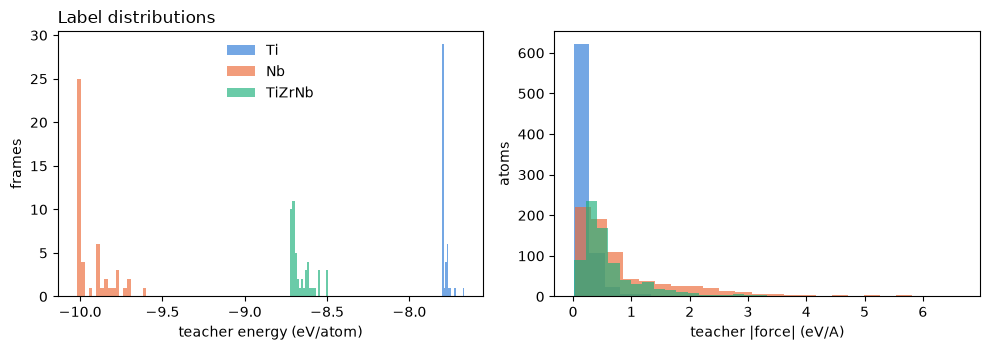

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for comp, color in zip(["Ti", "Nb", "TiZrNb"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    e = [fr.energy / fr.n_atoms for fr in frames if fr.composition == comp]
    axes[0].hist(e, bins=18, alpha=0.65, color=color, label=comp)
    f = np.concatenate([np.linalg.norm(fr.forces, axis=1)
                        for fr in frames if fr.composition == comp])
    axes[1].hist(f, bins=24, alpha=0.65, color=color, label=comp)
axes[0].set_xlabel("teacher energy (eV/atom)"); axes[0].set_ylabel("frames")
axes[1].set_xlabel("teacher |force| (eV/A)"); axes[1].set_ylabel("atoms")
axes[0].legend(frameon=False); axes[0].set_title("Label distributions", loc="left")
plt.tight_layout(); plt.show()

## Step 2: split by generation group and train the compact potential

The split moves whole batches into train or test, never random frames from
the same batch. The compact model is the repo's distilled potential:
element-resolved radial symmetry functions plus a small angular block,
one small network per element, forces by autograd.

In [4]:
split = group_split(frames, seed=0)
print(f"{len(split.train)} train / {len(split.val)} val / {len(split.test)} test frames")

model = build_model("compact", seed=0)
set_element_refs(model, fit_element_refs([frames[k] for k in split.train]))
train_fts = prepare_frames([frames[k] for k in split.train], model.cutoff, model.angular_cutoff)
val_fts = prepare_frames([frames[k] for k in split.val], model.cutoff, model.angular_cutoff)
model.fit_scaler(train_fts)
t0 = time.perf_counter()
hist = train_potential(model, train_fts, val_fts, epochs=30, lr=3e-3,
                       force_weight=1.0, batch_size=8, seed=0)
n_params = model.n_parameters()
print(f"trained {n_params} parameters in {time.perf_counter() - t0:.0f} s")

96 train / 24 val / 24 test frames


trained 6243 parameters in 30 s


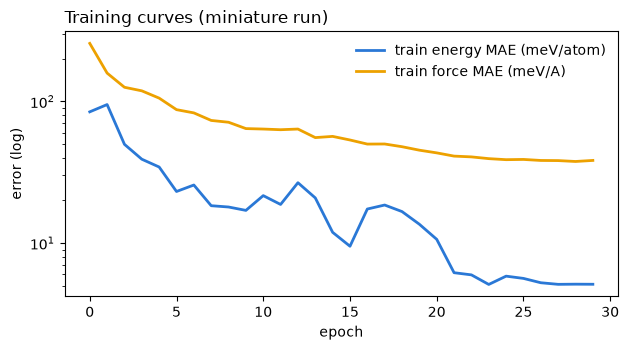

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(hist["epoch"], np.array(hist["train_e_mae"]) * 1000, color="#2a78d6", lw=2,
        label="train energy MAE (meV/atom)")
ax.plot(hist["epoch"], np.array(hist["train_f_mae"]) * 1000, color="#eda100", lw=2,
        label="train force MAE (meV/A)")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("error (log)")
ax.set_title("Training curves (miniature run)", loc="left")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## Step 3: evaluate on held-out groups and deploy as an ASE calculator

The parity plot uses only frames from batches the model never saw. The same
trained object then becomes a standard ASE calculator, which is the whole
deployment story of this repository: after this line, any ASE workflow
(optimizers, MD engines, property scripts) runs on the compact potential.

held-out miniature test: 14.2 meV/atom, 37 meV/A force MAE


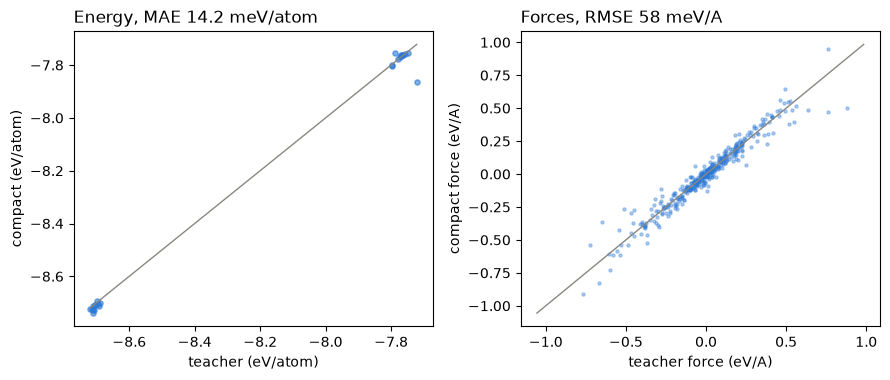

deployed: TorchPotentialCalculator with properties ['energy', 'free_energy', 'forces', 'stress']


In [6]:
test_fts = prepare_frames([frames[k] for k in split.test], model.cutoff, model.angular_cutoff)
m = evaluate_model(model, test_fts, collect_parity=True)
print(f"held-out miniature test: {m['e_mae_mev_atom']:.1f} meV/atom, "
      f"{m['f_mae_mev_a']:.0f} meV/A force MAE")

p = m["parity"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
et, ep = np.array(p["e_true_ev_atom"]), np.array(p["e_pred_ev_atom"])
axes[0].plot([et.min(), et.max()], [et.min(), et.max()], color="#898781", lw=1)
axes[0].scatter(et, ep, s=14, color="#2a78d6", alpha=0.6)
axes[0].set_xlabel("teacher (eV/atom)"); axes[0].set_ylabel("compact (eV/atom)")
axes[0].set_title(f"Energy, MAE {m['e_mae_mev_atom']:.1f} meV/atom", loc="left")
ft, fp = np.array(p["f_true_ev_a"]), np.array(p["f_pred_ev_a"])
axes[1].plot([ft.min(), ft.max()], [ft.min(), ft.max()], color="#898781", lw=1)
axes[1].scatter(ft[::3], fp[::3], s=5, color="#2a78d6", alpha=0.35)
axes[1].set_xlabel("teacher force (eV/A)"); axes[1].set_ylabel("compact force (eV/A)")
axes[1].set_title(f"Forces, RMSE {m['f_rmse_mev_a']:.0f} meV/A", loc="left")
plt.tight_layout(); plt.show()

calc = TorchPotentialCalculator(model, label="compact-mini")
print("deployed:", type(calc).__name__, "with properties", calc.implemented_properties)

## Step 4: a real property benchmark through the ASE interface

Equation of state of elemental Nb: the miniature compact potential against
its teacher, with the Materials Project DFT anchor marked. The anchor is the
only non-model number in the plot.

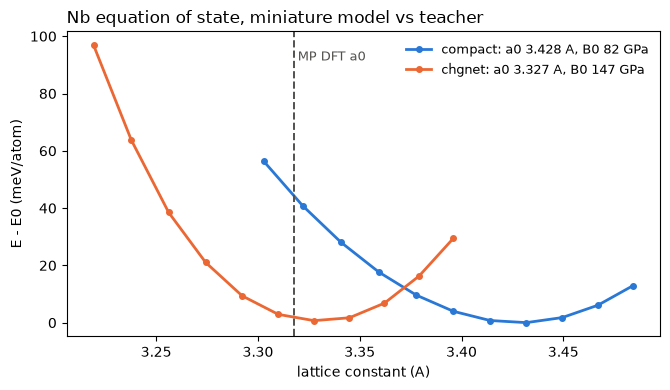

In [7]:
eos_c = eos_scan(calc, "Nb", reps=2, seed=rng_seed)
eos_t = eos_scan(teacher, "Nb", reps=2, seed=rng_seed)
anchors = load_anchors("data")
a_mp = anchors["anchors"]["Nb"]["a0_angstrom"]

fig, ax = plt.subplots(figsize=(6.8, 4.0))
for eos, name in ((eos_c, "compact"), (eos_t, "chgnet")):
    n = eos["n_atoms"]
    a = (2.0 * np.array(eos["volumes_a3"]) / n) ** (1 / 3)
    e = (np.array(eos["energies_ev"]) - eos["e0_ev"]) / n * 1000
    label = f"{name}: a0 {eos['a0_angstrom']:.3f} A, B0 {eos['b0_gpa']:.0f} GPa"
    ax.plot(a, e, color=COLOR[name], lw=2, marker="o", ms=4, label=label)
ax.axvline(a_mp, color=ANCHOR, ls="--", lw=1.4)
ax.text(a_mp, ax.get_ylim()[1] * 0.9, " MP DFT a0", color=ANCHOR, fontsize=9)
ax.set_xlabel("lattice constant (A)"); ax.set_ylabel("E - E0 (meV/atom)")
ax.set_title("Nb equation of state, miniature model vs teacher", loc="left")
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

## Step 5: the deployment gates, and the final metric

Two things a potential must earn before anyone runs MD with it: energy
conservation under NVE (the stability gate) and a measured cost per step.
Together with the force error from step 3 these place the miniature model
on the same accuracy-versus-speed axes the full benchmark uses.

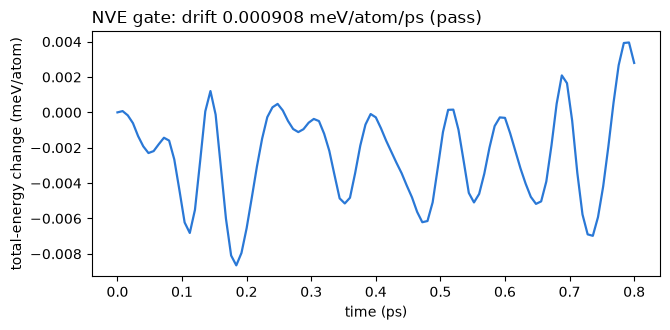

miniature-model final metrics (computed in this notebook):
  force RMSE vs teacher : 58 meV/A
  Nb a0 vs MP DFT       : 3.428 vs 3.3176 A
  NVE drift             : 0.000908 meV/atom/ps (pass)
  MD speed              : 0.326 ms/atom/step


In [8]:
nve = nve_drift(calc, "TiZrNb", a0=eos_c["a0_angstrom"], reps=2, seed=rng_seed,
                steps=400, record_every=4)
spd = speed_benchmark(calc, "TiZrNb", a0=eos_c["a0_angstrom"], reps=2, seed=rng_seed,
                      warmup_steps=5, timed_steps=50)
gate = "pass" if nve["gate_passed"] else "FAIL"
fig, ax = plt.subplots(figsize=(6.8, 3.4))
de = (np.array(nve["e_tot_ev_atom"]) - nve["e_tot_ev_atom"][0]) * 1000
ax.plot(nve["times_ps"], de, color="#2a78d6", lw=1.6)
ax.set_xlabel("time (ps)"); ax.set_ylabel("total-energy change (meV/atom)")
ax.set_title(f"NVE gate: drift {nve['drift_mev_atom_ps']:.3g} meV/atom/ps ({gate})",
             loc="left")
plt.tight_layout(); plt.show()

print("miniature-model final metrics (computed in this notebook):")
print(f"  force RMSE vs teacher : {m['f_rmse_mev_a']:.0f} meV/A")
print(f"  Nb a0 vs MP DFT       : {eos_c['a0_angstrom']:.3f} vs {a_mp} A")
print(f"  NVE drift             : {nve['drift_mev_atom_ps']:.3g} meV/atom/ps ({gate})")
print(f"  MD speed              : {spd['ms_per_atom_step']:.3f} ms/atom/step")

## The committed full benchmark

Everything above was a miniature run inside one notebook; the committed
benchmark trains on the full dataset (about 1,550 frames, 70 generation
groups, 9 compositions) and runs the whole property suite for four models.
The cell below replots the committed accuracy-versus-speed Pareto from
`results/metrics.json`; these numbers come from the full run, not from this
notebook. The teacher's zero force error is by construction, and MACE's
force number is model-to-model disagreement, not error against truth.

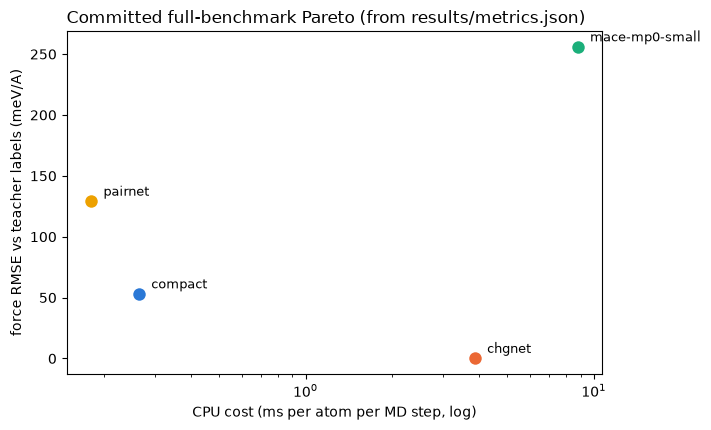

{
  "pairnet": {
    "ms_per_atom_step": 0.1802,
    "f_rmse_vs_teacher_mev_a": 129.1,
    "anchor_mean_abs_deviation_percent": 44.5,
    "n_parameters": 433
  },
  "compact": {
    "ms_per_atom_step": 0.264,
    "f_rmse_vs_teacher_mev_a": 53.0,
    "anchor_mean_abs_deviation_percent": 24.71,
    "n_parameters": 6243
  },
  "chgnet": {
    "ms_per_atom_step": 3.8585,
    "f_rmse_vs_teacher_mev_a": 0.0,
    "anchor_mean_abs_deviation_percent": 20.2,
    "n_parameters": 412525
  },
  "mace-mp0-small": {
    "ms_per_atom_step": 8.7794,
    "f_rmse_vs_teacher_mev_a": 255.9,
    "anchor_mean_abs_deviation_percent": 5.93,
    "n_parameters": 3847696
  }
}


In [9]:
metrics = json.loads(Path("results/metrics.json").read_text())
pareto = metrics["pareto"]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for name, p in pareto.items():
    if p["ms_per_atom_step"] is None or p["f_rmse_vs_teacher_mev_a"] is None:
        continue
    ax.scatter(p["ms_per_atom_step"], p["f_rmse_vs_teacher_mev_a"], s=110,
               color=COLOR[name], edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(name, (p["ms_per_atom_step"], p["f_rmse_vs_teacher_mev_a"]),
                textcoords="offset points", xytext=(9, 4), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("CPU cost (ms per atom per MD step, log)")
ax.set_ylabel("force RMSE vs teacher labels (meV/A)")
ax.set_title("Committed full-benchmark Pareto (from results/metrics.json)", loc="left")
plt.tight_layout(); plt.show()
print(json.dumps(pareto, indent=2))

That is the tradeoff this repository is about: the compact model gives up a
measured amount of fidelity to its teacher and, in exchange, steps MD an
order of magnitude faster on the same CPU. Whether that trade is worth it
depends on the property being computed, which is exactly what the full suite
in `results/` and `RESULTS.md` quantifies, property by property, against
Materials Project DFT anchors and cited experiments.